# 5.3 · Trenujemy mały Transformer

**Rozszerzenie · 60–90 minut · CPU, NumPy i Matplotlib.** W krótkim pokazie 20–25 min wystarczą zadanie, mapa maski, wykres treningu i dwie wygenerowane odpowiedzi. Uruchom notebook z katalogu, w którym leży plik mini_transformer_numpy.py.

W [5.1](Ch05_01_ile_glow_attention.ipynb) jedna głowa wybierała, skąd odczytać wartość. W [5.2](Ch05_02_blok_transformera.ipynb) policzyliśmy przejście przez blok. Teraz model **uczy się wag**, a potem generuje kolejne tokeny z samego promptu.

| Prompt | Oczekiwana kontynuacja |
| --- | --- |
| `<START> 0 1 a d LEWY` | `0 <KONIEC>` |
| `<START> 0 1 a d PRAWY` | `1 <KONIEC>` |

Polecenie `LEWY` wybiera pierwszy bit, `PRAWY` drugi. Litery służą jako tło. Oba bity, oba polecenia i wszystkie pojedyncze litery występują w każdym podziale. Całe **pary liter** rozdzielamy między train, walidację i test, więc ten sam prompt występuje tylko w jednym podziale.

**Pytanie na start.** Jeśli znasz wyłącznie ostatni token `LEWY`, czy przewidzisz odpowiedź? Ile trafień uzyskasz na zrównoważonym zbiorze?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mini_transformer_numpy import (
    ANSWER_POS, TOKEN_ID, Adam, MiniTransformer, decode, make_splits,
    measure, train_bigram,
)

data = make_splits()
x_train, y_train = data["train"]
x_val, y_val = data["val"]
print("Liczba sekwencji", {part: len(x) for part, (x, _) in data.items()})
print("Wejście:", decode(x_train[5]))
print("Cele:   ", decode(y_train[5]))

Liczba sekwencji {'train': 64, 'val': 32, 'test': 32}
Wejście: <START> 1 0 a a PRAWY 0
Cele:    1 0 a a PRAWY 0 <KONIEC>


## Od tokenu do celu

W przykładzie każda pełna sekwencja ma osiem tokenów. Tworzymy wejście i cele, przesuwając tę samą sekwencję o jeden token. Interesuje nas kontynuacja **od miejsca z poleceniem**. Na pierwszej z dwóch ocenianych pozycji oczekujemy bitu, na drugiej tokenu `<KONIEC>`.

| Pozycja w Pythonie | Co jest w wejściu | Czego uczymy model |
| --- | --- | --- |
| 0–4 | Początek, dwa bity, dwie litery | Ta część tworzy kontekst. Jej cele pomijamy w stracie. |
| 5 | Polecenie | Przewidź wybrany bit. |
| 6 | Prawidłowy bit podczas treningu | Przewidź koniec sekwencji. |

W treningu znamy poprawną kontynuację. Możemy policzyć logity równolegle dla całej sekwencji, jeśli każdy wiersz attention widzi tylko pozycję bieżącą i wcześniejsze. **Maska attention** ogranicza widoczne pozycje, a **wybór pozycji w stracie** ustala, które predykcje oceniamy.

## Co naprawdę trenujemy

To przyczynowy model z **jednym blokiem i jedną głową**. Kolejne operacje to embedding tokenu i pozycji, normalizacja, projekcje QKV, ważona suma $AV$, wyjście attention z połączeniem resztowym, normalizacja, dwie macierze FFN z ReLU, drugie połączenie resztowe i projekcja do słownika. LayerNorm działa osobno dla każdego tokenu. Pomijamy w nim uczoną skalę i przesunięcie. Warstwy liniowe mają tu same macierze wag.

W [kodzie pomocniczym](mini_transformer_numpy.py) można prześledzić forward i ręczne pochodne. Aktualizujemy także Q, K i V, więc wybór, skąd czytać, może się zmieniać podczas treningu.

Kształt logitów [batch, pozycja, słownik] (1, 7, 10)
Liczba parametrów 2480
Zmiana wcześniejszych logitów po zamianie przyszłego bitu 0.0


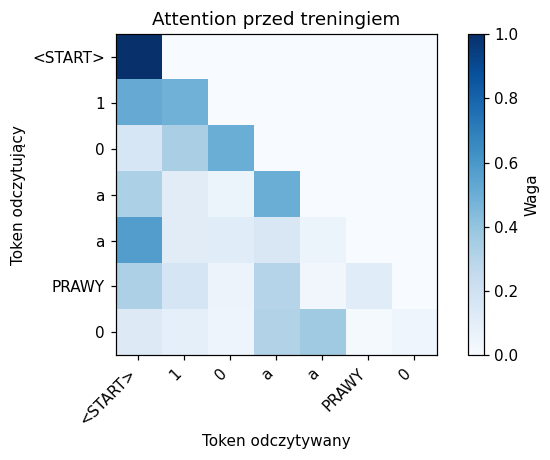

In [2]:
model = MiniTransformer(seed=2026)
example = x_train[5:6]
logits, attention, _ = model.forward(example)

changed = example.copy()
changed[0, -1] = TOKEN_ID["1"] if example[0, -1] == TOKEN_ID["0"] else TOKEN_ID["0"]
changed_logits, _, _ = model.forward(changed)
difference = np.abs(logits[:, :ANSWER_POS + 1] - changed_logits[:, :ANSWER_POS + 1]).max()

print("Kształt logitów [batch, pozycja, słownik]", logits.shape)
print("Liczba parametrów", sum(p.size for p in model.params.values()))
print("Zmiana wcześniejszych logitów po zamianie przyszłego bitu", difference)

labels = [decode([token]) for token in example[0]]
fig, ax = plt.subplots(figsize=(6.3, 4.3))
image = ax.imshow(attention[0], cmap="Blues", vmin=0, vmax=1)
ax.set(title="Attention przed treningiem", xlabel="Token odczytywany", ylabel="Token odczytujący")
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
fig.colorbar(image, ax=ax, label="Waga")
fig.tight_layout()
plt.show()

## Jeden krok i cała pętla

Dla pozycji $t$ z celem $y_t$ strata wynosi $-\log p_\theta(y_t\mid x_{\le t})$. Uśredniamy ją po dwóch ocenianych pozycjach i po przykładach. Trafność liczymy **tylko na bicie**, bo łatwy token `<KONIEC>` zawyżyłby wynik bazowy.

Backprop przekazuje pochodne od straty przez wyjście słownikowe, FFN, attention i embeddingi. Adam wykorzystuje je do aktualizacji parametrów. Dla przejrzystości każdy krok używa pełnego zbioru treningowego. Walidację odczytujemy co dziesięć kroków bez aktualizacji wag.

Strata treningowa 2.185 → 0.0001
Trafność walidacyjna na bicie 0% → 100%
Zmiana macierzy Q (norma Frobeniusa) 1.297


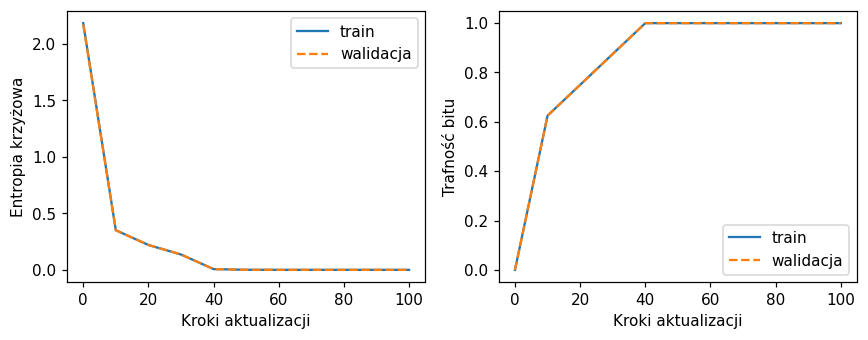

In [3]:
model = MiniTransformer(seed=2026)
optimizer = Adam(model.params, lr=0.005)
initial_q = model.params["Q"].copy()
history = [(0, *measure(model, x_train, y_train), *measure(model, x_val, y_val))]

for step in range(1, 101):
    loss, gradients = model.loss_and_gradients(x_train, y_train)
    optimizer.step(gradients)
    if step % 10 == 0:
        history.append((step, *measure(model, x_train, y_train), *measure(model, x_val, y_val)))

steps, train_loss, train_acc, val_loss, val_acc = np.array(history).T
print(f"Strata treningowa {train_loss[0]:.3f} → {train_loss[-1]:.4f}")
print(f"Trafność walidacyjna na bicie {val_acc[0]:.0%} → {val_acc[-1]:.0%}")
print(f"Zmiana macierzy Q (norma Frobeniusa) {np.linalg.norm(model.params['Q'] - initial_q):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, train_values, val_values, ylabel in (
    (axes[0], train_loss, val_loss, "Entropia krzyżowa"),
    (axes[1], train_acc, val_acc, "Trafność bitu"),
):
    ax.plot(steps, train_values, label="train")
    ax.plot(steps, val_values, "--", label="walidacja")
    ax.set(xlabel="Kroki aktualizacji", ylabel=ylabel)
    ax.legend()
fig.tight_layout()
plt.show()

## Jedna miara, dwa modele

Model bazowy **bigram** wybiera najczęstszy następny token w treningu dla każdego bieżącego tokenu. Po `LEWY` i `PRAWY` oba bity są równie prawdopodobne. Przy ustalonej regule rozstrzygania remisów bigram osiągnie 50% na zrównoważonym zbiorze.

Dopiero teraz oceniamy oba modele na teście. Przykłady z testu nie uczestniczą w aktualizacji wag ani w obserwowanej krzywej walidacyjnej. Porównujemy trafność bitu na tych samych 32 promptach.

In [4]:
x_test, y_test = data["test"]
bigram = train_bigram(x_train, y_train)
baseline_acc = (bigram[x_test[:, ANSWER_POS]] == y_test[:, ANSWER_POS]).mean()
test_loss, test_acc = measure(model, x_test, y_test)
print(f"Bigram · trafność bitu {baseline_acc:.1%}")
print(f"Transformer · trafność bitu {test_acc:.1%} · strata {test_loss:.4f}")

Bigram · trafność bitu 50.0%
Transformer · trafność bitu 100.0% · strata 0.0001


## Generowanie bez gotowej odpowiedzi

W treningu drugi oceniany krok otrzymuje prawidłowy bit. W generowaniu podajemy sam prompt. Model wybiera token o najwyższym logicie, dopisuje go do sekwencji i dopiero wtedy wyznacza kolejny token. Zamienimy wyłącznie polecenie, więc zmiana odpowiedzi powinna wynikać z wyboru pozycji.

In [5]:
for command in ("LEWY", "PRAWY"):
    prompt = ["<START>", "0", "1", "a", "d", command]
    prefix = [TOKEN_ID[token] for token in prompt]
    result = model.generate(prefix, max_new=2)
    print(decode(result))

<START> 0 1 a d LEWY 0 <KONIEC>
<START> 0 1 a d PRAWY 1 <KONIEC>


## Ćwiczenia po uruchomieniu

1. Wskaż w tablicy `y_train` dwie pozycje używane w stracie. Wyjaśnij, dlaczego zamiana tokenu na pozycji 6 nie wpływa na logity pozycji 5.
2. Dla bitów `1 0` przewidź obie kontynuacje, a potem wykonaj generowanie. Zmień wyłącznie parę liter na `b a` i sprawdź, czy odpowiedź nadal jest zgodna z poleceniem.
3. Porównaj przebiegi z 20 i 100 krokami na tych samych wagach początkowych. Wnioskuj z walidacji. W tej próbie sprawdzamy wpływ budżetu treningu i nie stroimy liczby kroków na teście.

**Dalej dla chętnych.** Porównaj uczenie wszystkich wag z wariantem o zamrożonych Q i K. W drugim wariancie usuń klucze Q i K ze słownika gradientów przed wywołaniem Adam. Zostaw te same pozostałe ustawienia i powtórz dla kilku inicjalizacji. Zanotuj trafność na walidacji i wagi attention w wierszu polecenia dla obu bitów. Wartość wagi attention opisuje odczyt tej głowy. W modelu informacja przechodzi też przez FFN i ścieżki resztowe.